# Capstone — Initial Report & Exploratory Data Analysis
## What Drives the Price of a Home?

**Research question:** *Which physical and locational characteristics of a residential home
most influence its sale price, and how accurately can those characteristics predict a home's
market value?*

This notebook performs data cleaning, exploratory data analysis (EDA), feature engineering,
and builds a **baseline regression model** that later modules will improve upon. The dataset
is the Ames, Iowa housing dataset (Kaggle *House Prices*), with 1,460 residential sales
described by 79 explanatory features.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
RANDOM_STATE = 42

## 1. Load the Data

The Ames training file has one row per sale, a `SalePrice` target, and 79 descriptive
columns (`Id` is just an index).

In [2]:
df = pd.read_csv('data/train.csv')
print('Shape:', df.shape)
df.head()

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
TARGET = 'SalePrice'
if 'Id' in df.columns:
    df = df.drop(columns=['Id'])
print('Number of features:', df.shape[1] - 1)
df[TARGET].describe()

Number of features: 79


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

## 2. Data Quality: Missing Values & Duplicates

In the Ames data, many "missing" values are not truly missing — for features like `PoolQC`,
`Alley`, or `BsmtQual`, `NaN` means the house simply lacks that feature. We handle those
meaningfully rather than dropping them.

In [4]:
dupes = df.duplicated().sum()
print('Duplicate rows:', dupes)
df = df.drop_duplicates()

Duplicate rows: 0


In [5]:
missing = df.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
print('Columns with missing values:', len(missing))
missing.head(20)

Columns with missing values: 19


PoolQC          0.995205
MiscFeature     0.963014
Alley           0.937671
Fence           0.807534
MasVnrType      0.597260
FireplaceQu     0.472603
LotFrontage     0.177397
GarageQual      0.055479
GarageType      0.055479
GarageFinish    0.055479
GarageCond      0.055479
GarageYrBlt     0.055479
BsmtExposure    0.026027
BsmtFinType2    0.026027
BsmtQual        0.025342
BsmtFinType1    0.025342
BsmtCond        0.025342
MasVnrArea      0.005479
Electrical      0.000685
dtype: float64

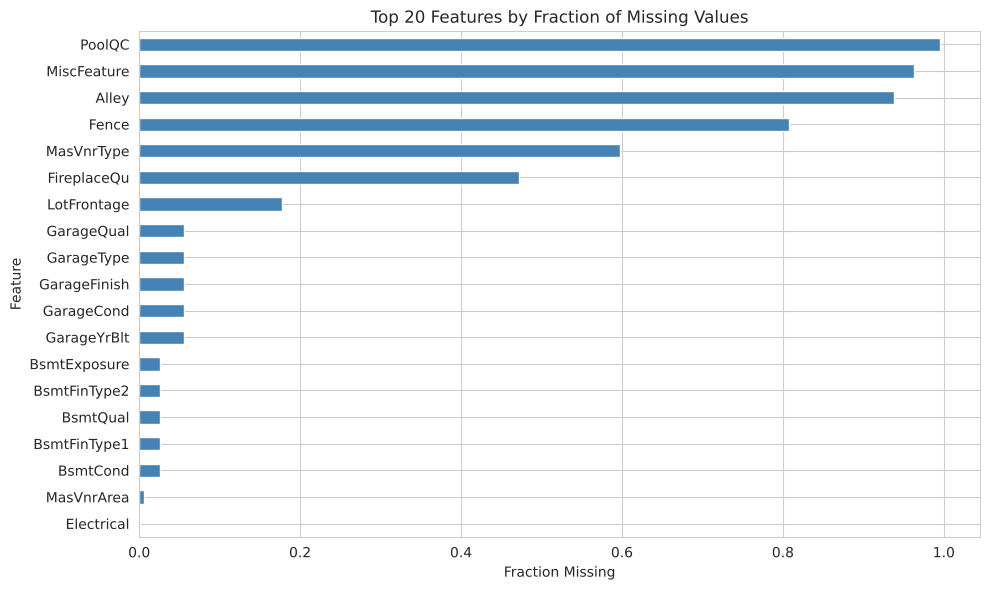

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
missing.head(20).plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Top 20 Features by Fraction of Missing Values')
ax.set_xlabel('Fraction Missing'); ax.set_ylabel('Feature')
ax.invert_yaxis()
plt.tight_layout(); plt.show()

### Handling missing values

- **Categorical features where NaN means "none"** are filled with `'None'`.
- **Numeric features tied to an absent feature** are filled with `0`.
- **`LotFrontage`** is filled with the neighborhood median.
- Any remaining numeric NaNs get the column median; remaining categoricals get the mode.

In [7]:
df_clean = df.copy()
none_cols = ['Alley','MasVnrType','BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1',
             'BsmtFinType2','FireplaceQu','GarageType','GarageFinish','GarageQual',
             'GarageCond','PoolQC','Fence','MiscFeature']
for c in none_cols:
    if c in df_clean.columns:
        df_clean[c] = df_clean[c].fillna('None')

zero_cols = ['MasVnrArea','GarageYrBlt','GarageArea','GarageCars','BsmtFinSF1','BsmtFinSF2',
             'BsmtUnfSF','TotalBsmtSF','BsmtFullBath','BsmtHalfBath']
for c in zero_cols:
    if c in df_clean.columns:
        df_clean[c] = df_clean[c].fillna(0)

if 'LotFrontage' in df_clean.columns:
    df_clean['LotFrontage'] = df_clean.groupby('Neighborhood')['LotFrontage'].transform(
        lambda s: s.fillna(s.median()))

for c in df_clean.select_dtypes(include=np.number).columns:
    df_clean[c] = df_clean[c].fillna(df_clean[c].median())
for c in df_clean.select_dtypes(include='object').columns:
    if df_clean[c].isna().any():
        df_clean[c] = df_clean[c].fillna(df_clean[c].mode()[0])

print('Remaining missing values:', int(df_clean.isna().sum().sum()))

Remaining missing values: 0


/tmp/ipykernel_2468/489929572.py:21: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in df_clean.select_dtypes(include='object').columns:


## 3. The Target: Sale Price

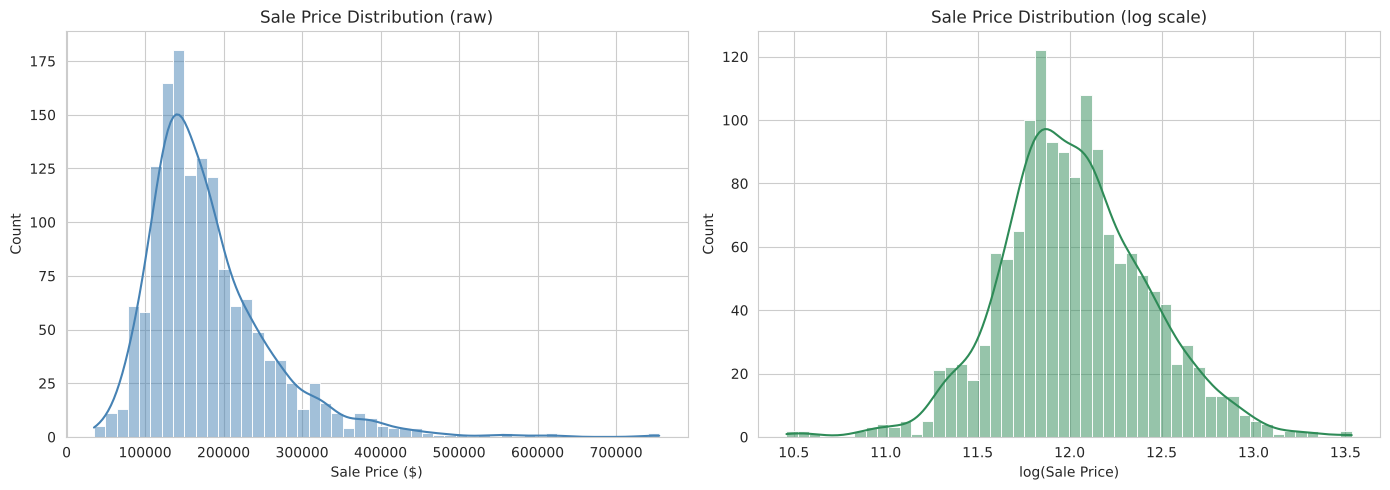

Skew (raw): 1.883
Skew (log): 0.121


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_clean[TARGET], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Sale Price Distribution (raw)'); axes[0].set_xlabel('Sale Price ($)')
sns.histplot(np.log1p(df_clean[TARGET]), bins=50, kde=True, ax=axes[1], color='seagreen')
axes[1].set_title('Sale Price Distribution (log scale)'); axes[1].set_xlabel('log(Sale Price)')
plt.tight_layout(); plt.show()
print('Skew (raw):', round(df_clean[TARGET].skew(), 3))
print('Skew (log):', round(np.log1p(df_clean[TARGET]).skew(), 3))

Sale price is strongly right-skewed; the log transform makes it near-symmetric. We model
**log(SalePrice)**, which stabilizes variance and keeps expensive homes from dominating error.

### Outlier analysis

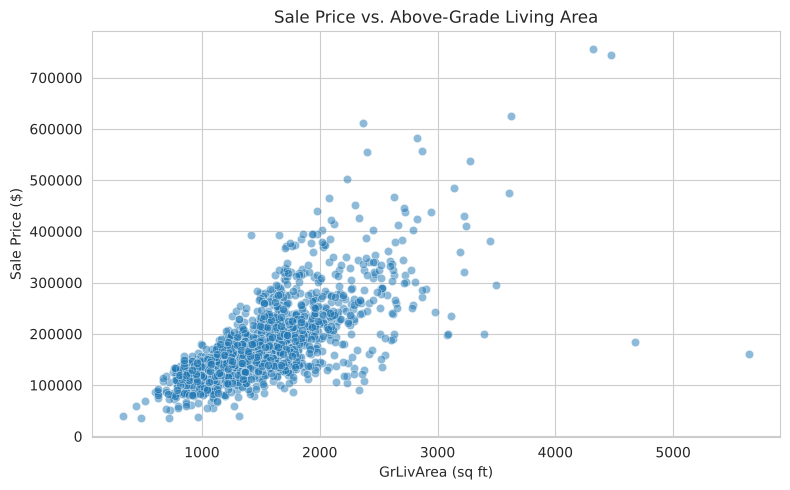

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df_clean, x='GrLivArea', y=TARGET, alpha=0.5, ax=ax)
ax.set_title('Sale Price vs. Above-Grade Living Area')
ax.set_xlabel('GrLivArea (sq ft)'); ax.set_ylabel('Sale Price ($)')
plt.tight_layout(); plt.show()

In [10]:
before = len(df_clean)
df_clean = df_clean[~((df_clean['GrLivArea'] > 4000) & (df_clean[TARGET] < 300000))]
print(f'Removed {before - len(df_clean)} outlier rows; {len(df_clean)} remain.')

Removed 2 outlier rows; 1458 remain.


## 4. Exploratory Data Analysis
### Which numeric features correlate most with price?

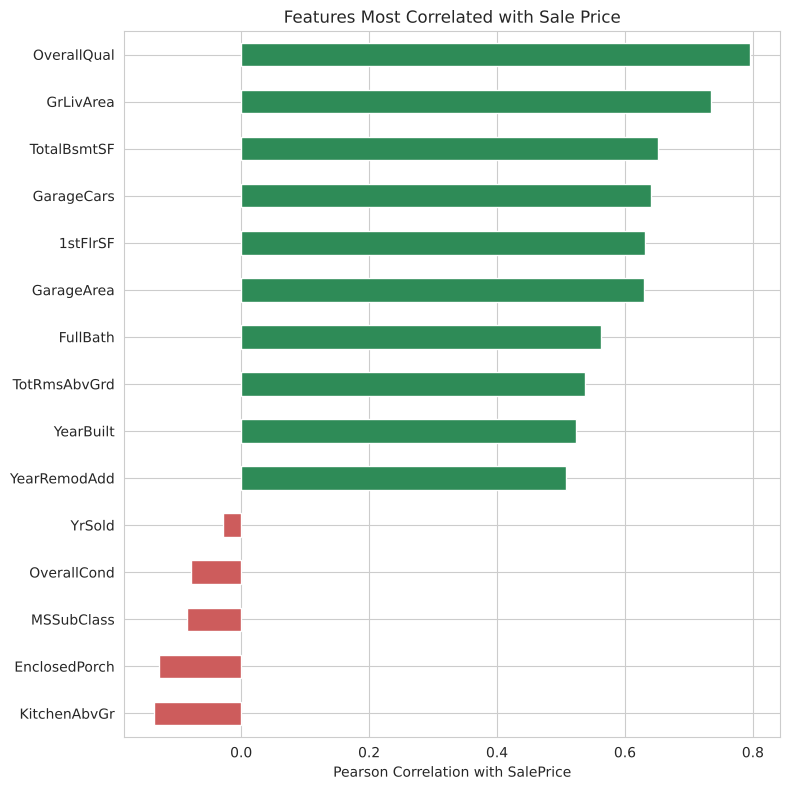

OverallQual     0.795774
GrLivArea       0.734968
TotalBsmtSF     0.651153
GarageCars      0.641047
1stFlrSF        0.631530
GarageArea      0.629217
FullBath        0.562165
TotRmsAbvGrd    0.537769
YearBuilt       0.523608
YearRemodAdd    0.507717
Name: SalePrice, dtype: float64

In [11]:
num_df = df_clean.select_dtypes(include=np.number)
corr_to_price = num_df.corr()[TARGET].drop(TARGET).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 8))
top_corr = pd.concat([corr_to_price.head(10), corr_to_price.tail(5)])
colors = ['seagreen' if v > 0 else 'indianred' for v in top_corr]
top_corr.plot(kind='barh', ax=ax, color=colors)
ax.set_title('Features Most Correlated with Sale Price')
ax.set_xlabel('Pearson Correlation with SalePrice'); ax.invert_yaxis()
plt.tight_layout(); plt.show()
corr_to_price.head(10)

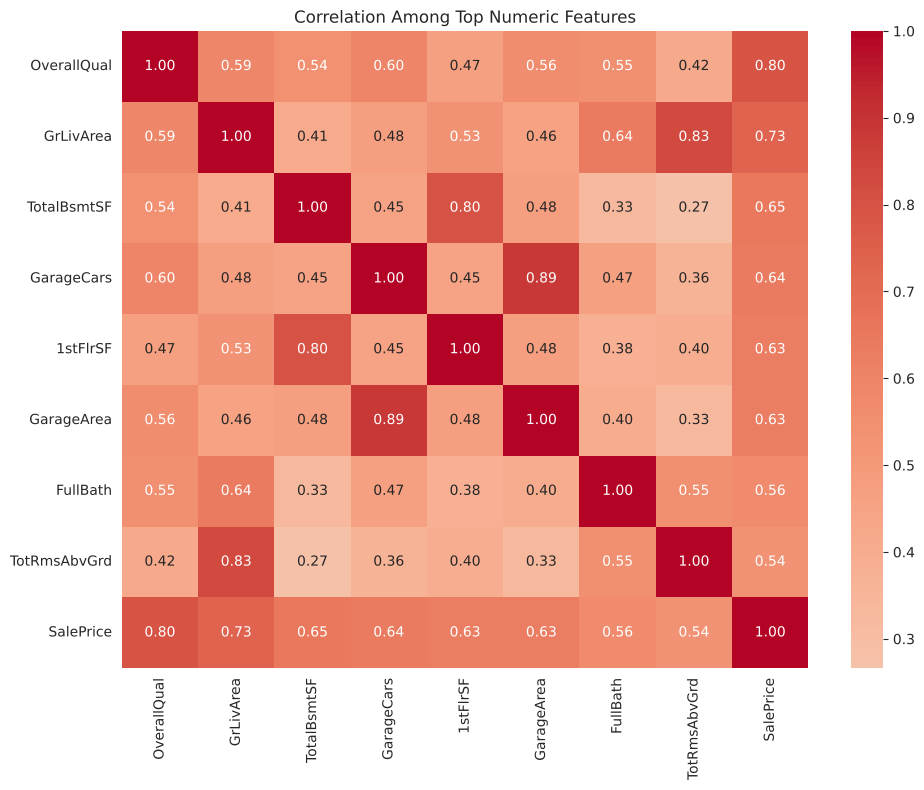

In [12]:
top_features = corr_to_price.head(8).index.tolist() + [TARGET]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(df_clean[top_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Among Top Numeric Features')
plt.tight_layout(); plt.show()

### Continuous drivers vs. price

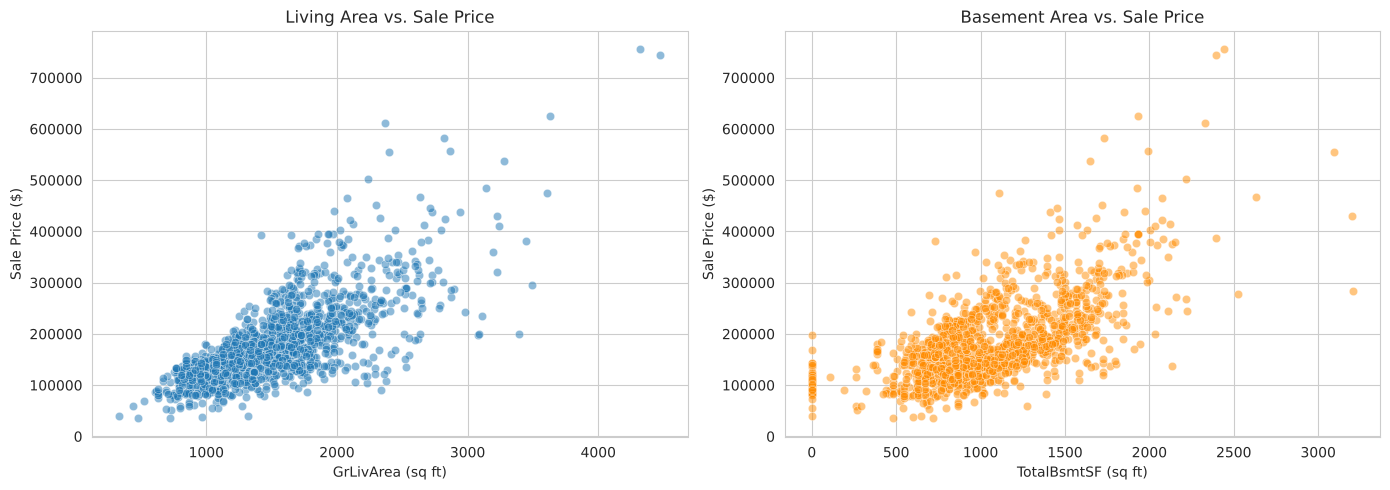

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df_clean, x='GrLivArea', y=TARGET, alpha=0.5, ax=axes[0])
axes[0].set_title('Living Area vs. Sale Price')
axes[0].set_xlabel('GrLivArea (sq ft)'); axes[0].set_ylabel('Sale Price ($)')
sns.scatterplot(data=df_clean, x='TotalBsmtSF', y=TARGET, alpha=0.5, ax=axes[1], color='darkorange')
axes[1].set_title('Basement Area vs. Sale Price')
axes[1].set_xlabel('TotalBsmtSF (sq ft)'); axes[1].set_ylabel('Sale Price ($)')
plt.tight_layout(); plt.show()

### Categorical drivers vs. price

/tmp/ipykernel_2468/2065837237.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='OverallQual', y=TARGET, ax=axes[0], palette='viridis')


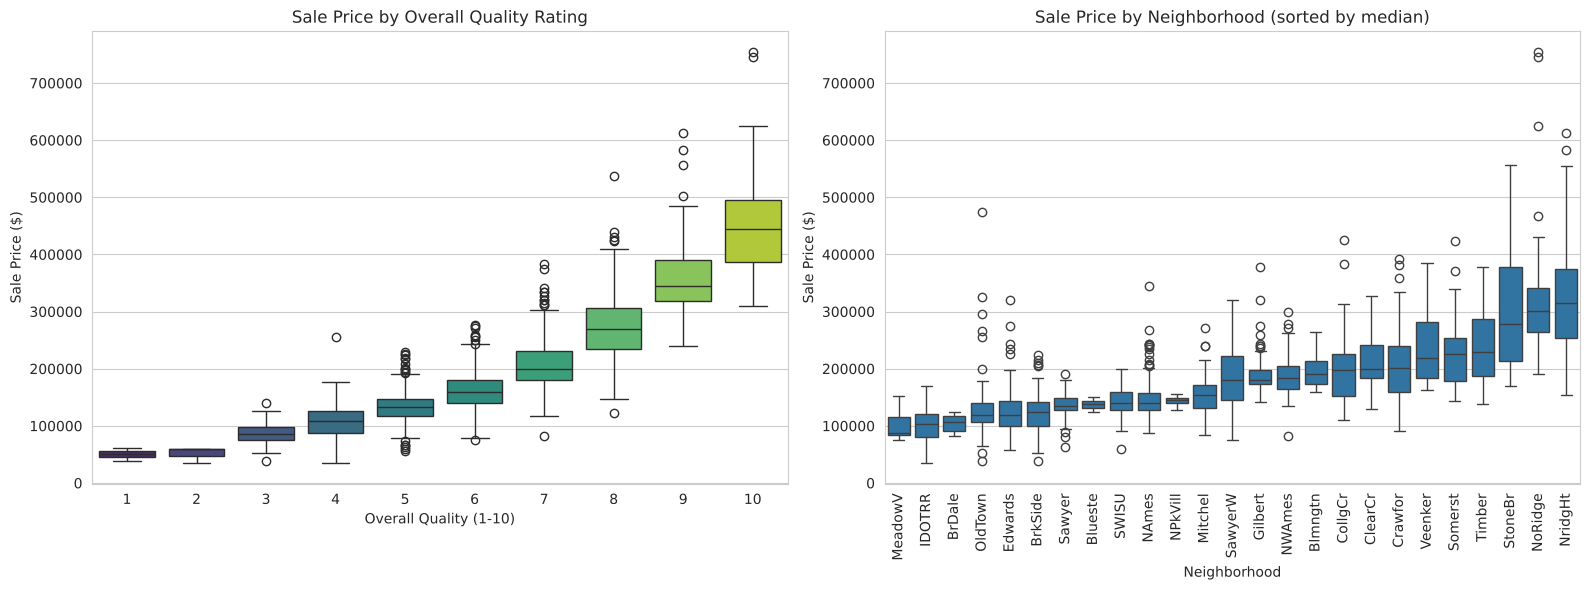

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df_clean, x='OverallQual', y=TARGET, ax=axes[0], palette='viridis')
axes[0].set_title('Sale Price by Overall Quality Rating')
axes[0].set_xlabel('Overall Quality (1-10)'); axes[0].set_ylabel('Sale Price ($)')
order = df_clean.groupby('Neighborhood')[TARGET].median().sort_values().index
sns.boxplot(data=df_clean, x='Neighborhood', y=TARGET, order=order, ax=axes[1])
axes[1].set_title('Sale Price by Neighborhood (sorted by median)')
axes[1].set_xlabel('Neighborhood'); axes[1].set_ylabel('Sale Price ($)')
axes[1].tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.show()

## 5. Feature Engineering

We derive features that domain knowledge suggests should matter:
- **`HouseAge`** — years between construction and sale.
- **`TotalSF`** — total finished square footage.
- **`TotalBath`** — all bathrooms combined.
- **`RemodAge`** — years since last remodel.
- **`HasGarage` / `HasPool`** — indicators of premium features.

In [15]:
fe = df_clean.copy()
fe['HouseAge'] = (fe['YrSold'] - fe['YearBuilt']).clip(lower=0)
fe['RemodAge'] = (fe['YrSold'] - fe['YearRemodAdd']).clip(lower=0)
fe['TotalSF'] = fe['TotalBsmtSF'] + fe['1stFlrSF'] + fe['2ndFlrSF']
fe['TotalBath'] = (fe['FullBath'] + 0.5*fe['HalfBath'] + fe['BsmtFullBath'] + 0.5*fe['BsmtHalfBath'])
fe['HasGarage'] = (fe['GarageArea'] > 0).astype(int)
fe['HasPool'] = (fe['PoolArea'] > 0).astype(int)
new_feats = ['HouseAge', 'RemodAge', 'TotalSF', 'TotalBath', 'HasGarage', 'HasPool']
fe[new_feats + [TARGET]].head()

,HouseAge,RemodAge,TotalSF,TotalBath,HasGarage,HasPool,SalePrice
0,5,5,2566,3.5,1,0,208500
1,31,31,2524,2.5,1,0,181500
2,7,6,2706,3.5,1,0,223500
3,91,36,2473,2.0,1,0,140000
4,8,8,3343,3.5,1,0,250000


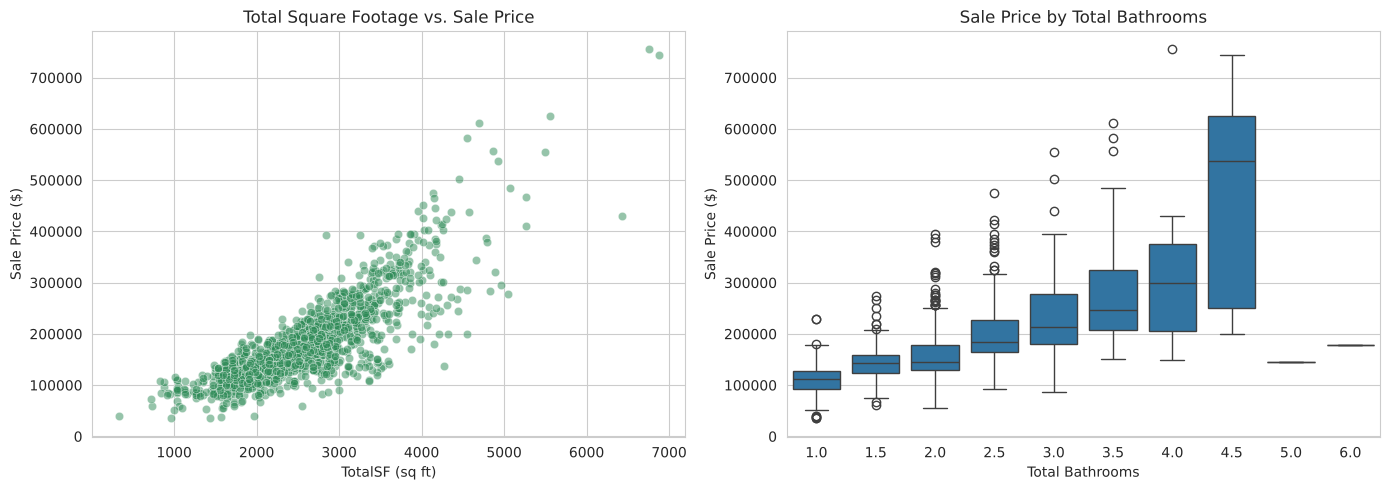

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=fe, x='TotalSF', y=TARGET, alpha=0.5, ax=axes[0], color='seagreen')
axes[0].set_title('Total Square Footage vs. Sale Price')
axes[0].set_xlabel('TotalSF (sq ft)'); axes[0].set_ylabel('Sale Price ($)')
sns.boxplot(data=fe, x='TotalBath', y=TARGET, ax=axes[1])
axes[1].set_title('Sale Price by Total Bathrooms')
axes[1].set_xlabel('Total Bathrooms'); axes[1].set_ylabel('Sale Price ($)')
plt.tight_layout(); plt.show()

## 6. Baseline Model

We build a baseline **regression** model to predict `log(SalePrice)` using **Ridge
regression** inside a preprocessing pipeline (impute + scale numeric, one-hot encode
categorical).

**Evaluation metric: RMSE on log(SalePrice)**, with R² and MAE as supporting metrics. RMSE
penalizes large dollar errors more heavily — important because a big miss on an expensive
home is costly — and working in log space means the metric reflects *percentage* error, so it
isn't dominated by the most expensive houses. This is the baseline Module 24 will improve on.

In [17]:
y = np.log1p(fe[TARGET])
X = fe.drop(columns=[TARGET])
num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(include='object').columns.tolist()
preprocessor = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), num_features),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('encode', OneHotEncoder(handle_unknown='ignore'))]), cat_features)])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (1166, 85)  Test: (292, 85)


/tmp/ipykernel_2468/1454116768.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = X.select_dtypes(include='object').columns.tolist()


In [18]:
baseline = Pipeline([('prep', preprocessor), ('model', Ridge(alpha=10.0))])
baseline.fit(X_train, y_train)
cv_rmse = -cross_val_score(baseline, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
print(f'CV RMSE (log): {cv_rmse.mean():.4f} (+/- {cv_rmse.std():.4f})')

CV RMSE (log): 0.1147 (+/- 0.0093)


In [19]:
test_pred = baseline.predict(X_test)
rmse_log = np.sqrt(mean_squared_error(y_test, test_pred))
mae_log = mean_absolute_error(y_test, test_pred)
r2 = r2_score(y_test, test_pred)
print(f'Test RMSE (log) : {rmse_log:.4f}')
print(f'Test MAE  (log) : {mae_log:.4f}')
print(f'Test R2         : {r2:.4f}')
pred_dollars = np.expm1(test_pred); true_dollars = np.expm1(y_test)
rmse_dollars = np.sqrt(mean_squared_error(true_dollars, pred_dollars))
mae_dollars = mean_absolute_error(true_dollars, pred_dollars)
print(f'Test RMSE (dollars): ${rmse_dollars:,.0f}')
print(f'Test MAE  (dollars): ${mae_dollars:,.0f}')

Test RMSE (log) : 0.1232
Test MAE  (log) : 0.0864
Test R2         : 0.9099
Test RMSE (dollars): $20,071
Test MAE  (dollars): $14,567


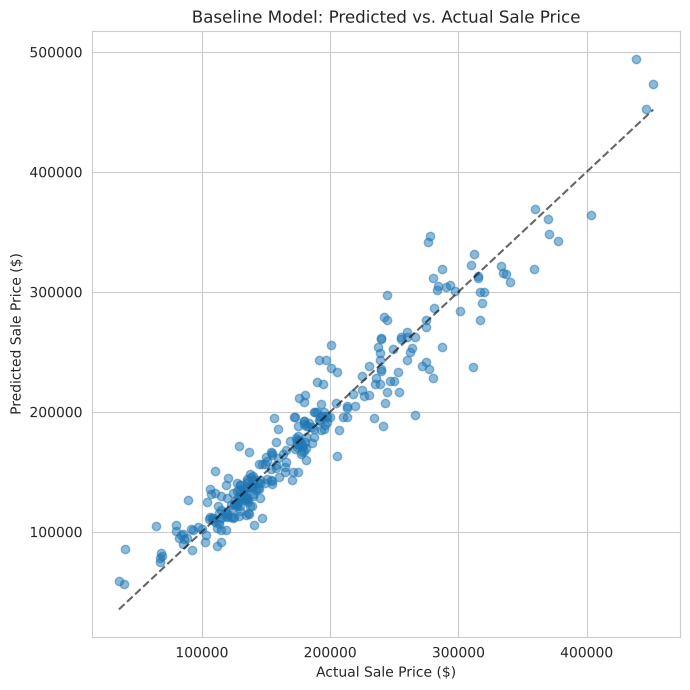

In [20]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(true_dollars, pred_dollars, alpha=0.5)
lims = [true_dollars.min(), true_dollars.max()]
ax.plot(lims, lims, 'k--', alpha=0.6)
ax.set_title('Baseline Model: Predicted vs. Actual Sale Price')
ax.set_xlabel('Actual Sale Price ($)'); ax.set_ylabel('Predicted Sale Price ($)')
plt.tight_layout(); plt.show()

## 7. Initial Findings

- **Sale price is strongly right-skewed** (skew 1.88); modeling `log(SalePrice)` gives a
  near-symmetric target (skew 0.12) and a percentage-based error that doesn't let luxury
  homes dominate.
- **Overall quality (r = 0.80), total/above-grade living area (GrLivArea r = 0.74), basement
  and first-floor size, and garage capacity** are the strongest numeric drivers of price.
  Neighborhood also produces large, consistent differences in median price.
- **Two documented outliers** (very large homes sold cheaply) were removed per the dataset
  author's guidance; the data was otherwise complete after meaningful imputation (0 remaining
  missing values, 0 duplicates).
- **Feature engineering added signal:** `TotalSF`, `TotalBath`, and `HouseAge` each track
  price clearly and combine several raw columns into stronger predictors.
- **Baseline model:** a Ridge regression on log-price achieved a cross-validated RMSE of
  **0.1147** (log units) and a test-set **R² of 0.910** — about **\$20,071** RMSE and
  **\$14,567** MAE in dollar terms. This is the benchmark for Module 24.

### Next steps (Module 24)
- Compare against Lasso, Random Forest, and Gradient Boosting.
- Tune hyperparameters with grid search.
- Use Lasso / tree importances to produce a clean, ranked driver list for a non-technical
  audience, and translate the error into business terms (pricing confidence bands).